# KQC Shaping — one Swissmon with two Purcell-filtered λ/4 resonators (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/shaping.py` (class `Shaping`, default parameters `tunable = False`, chip
name "CTest"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/shaping.py`; spec `docs/designs/kqc/test_chips.md`, row
*Shaping*). A Swissmon ("Finnmon") at (4000, 5000) µm, rotated 270°, with a charge line from WN and a flux line from
WS. Its coupler 0 (up) feeds the **readout** chain and its coupler 2 (down) the mirrored **shaping** chain. Each
chain is a λ/4 resonator drawn as straight → T → meander → T → shorted stub (KQC segment targets "from qubit to
shorted end" 611.586 / 1834.76 / 611.586 µm, and 634.71 / 1904.13 / 634.71 µm for the shaping chain), with a drive
gap capacitor on the first T (input from NW / SW) and a gap capacitor J on the second T into a λ/4 **Purcell
filter** (T → shorted stub one way, meander → κ interdigital capacitor → output EN / ES the other; targets
3158.32 / 789.581 and 3253.65 / 813.413 µm "from output to shorted end").

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (the SMA8 launchers sit on its edges), Quantcore die frame, device ID "CTest" |
| launchers | SMA8, all eight (NE and SE carry nothing with `tunable = False`), `launcher_indent` 800 µm | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junction | KQC Manhattan SQUID (assumed L_J 12 nH, C_J 2 fF) | Quantcore trilayer SQUID, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH, C_J 15 fF |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; every straight with KQC's length formula; the launcher legs from the launcher ports |
| placement | centred | centred (checked below) |

**Kept exactly (same KQC cells, parameters and positions):** the `Swissmon` with KQC's arm, gap and coupler
lists; the six `WaveguideCoplanarSplitter`s (lengths 61/61/31 µm, ports right/left/bottom) placed as KQC places them
(T a: its port at the end of the first straight; T b: at the meander end; T c: snapped to capacitor J); the six
`FingerCapacitorSquare`s from KQC's `cap_params` (J gap 37.5 / 36.8 µm, κ interdigital 4 × 67.9 / 71.5 µm, drive
gap 36.2 µm), snapped port `a` to the T's as KQC aligns them; the charge line (6 µm open end), flux line, drive lines
and output lines along KQC's paths.

**Substituted:** KQC's four `Meander` cells (start, end, length, `meanders` = 2 / 3) are CPW routes T ↔ T (and T ↔ κ
capacitor, merged with the 400 µm Purcell leg) whose waypoints are the centre line KQC's `Meander` computes for the
same arguments (built in a scratch layout). Two reasons: (1) as a separate `Meander` instance the LOM would make each
one a λ/2 bus between the two T's, not part of the λ/4; (2) a Designer `meander` route also is a λ/2 bus and would
not reproduce KQC's shape. The meander leaves the T after 115 µm (150 µm for the Purcell meander), shorter than the
router's port stub plus a bend (2r = 200 µm), so these routes take `r = 10` µm for the router's port stubs and draw
with KQC's r = 100 µm (`params={"r": 100}`); the path is KQC's, which needs only 100 µm before each bend.

**LOM approximation (stated):** the builder makes each chain's routes one λ/4 `TLres` of the summed route length
(the wires join it to its coupler end) and attaches the drive and J capacitors there, i.e. at the open end, not at
their taps. The T's arms are not counted (≈ 300 µm per resonator, table in LOM 1), and the tapped coupling is
overestimated. The numbers are therefore rough: the mode structure (qubit, two readouts, two Purcell filters) is
right, the couplings are not to be trusted.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its eight SMA8 launchers, the launchers and the pad rule, the Swissmon (first: both readout chains start at its couplers), the two chains element by element (readout λ/4, J capacitor, Purcell filter, output and drive lines), the charge and flux lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `shaping.v1.ipynb`; both save the same `shaping.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/shaping/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/shaping")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the qubit, its readout, the
control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far (live, KLayout
redraws after every cell).

**Why the readout comes after the qubit, in one piece.** Every element of a chain is placed on a port of the one
before it, as KQC builds it: the first T at the end of the straight from the qubit's coupler, the meander from that T,
the second T at the meander's end, the J capacitor on it, and so on out to the output launcher. Chain B also reuses a
length chain A computes (`wg2_len`, the 400 µm Purcell leg). So the chains follow the qubit and keep the v1's call
order, chain A before chain B; nothing is recomputed to split them. KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 sample holder's eight launchers |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the readout line: nothing yet (every readout element hangs on the qubit, Design 5) |
| 4 | the qubit: the Swissmon with its trilayer SQUID (and KQC's helper functions for the chains) |
| 5 | the readout: chain A (up from coupler 0) and the mirrored chain B (down from coupler 2), each a λ/4 readout, a J capacitor, a λ/4 Purcell filter with its κ capacitor and output line, and a drive line |
| 6 | the coupling: nothing beyond the chains' capacitors (one qubit) |
| 7 | the control routing: the charge line from WN and the flux line from WS |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the chip: the 10 × 10 mm box, all eight SMA8 launchers (KQC's default names NW, NE, EN, ES,
SE, SW, WS, WN) and the chip name "CTest" (the device ID). `with_grid=True` asks for KQC's whole-area ground grid
(the original's cheese): the PDK band is then not added. The frame is the PDK default (L dicing markers 1000/0,
3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

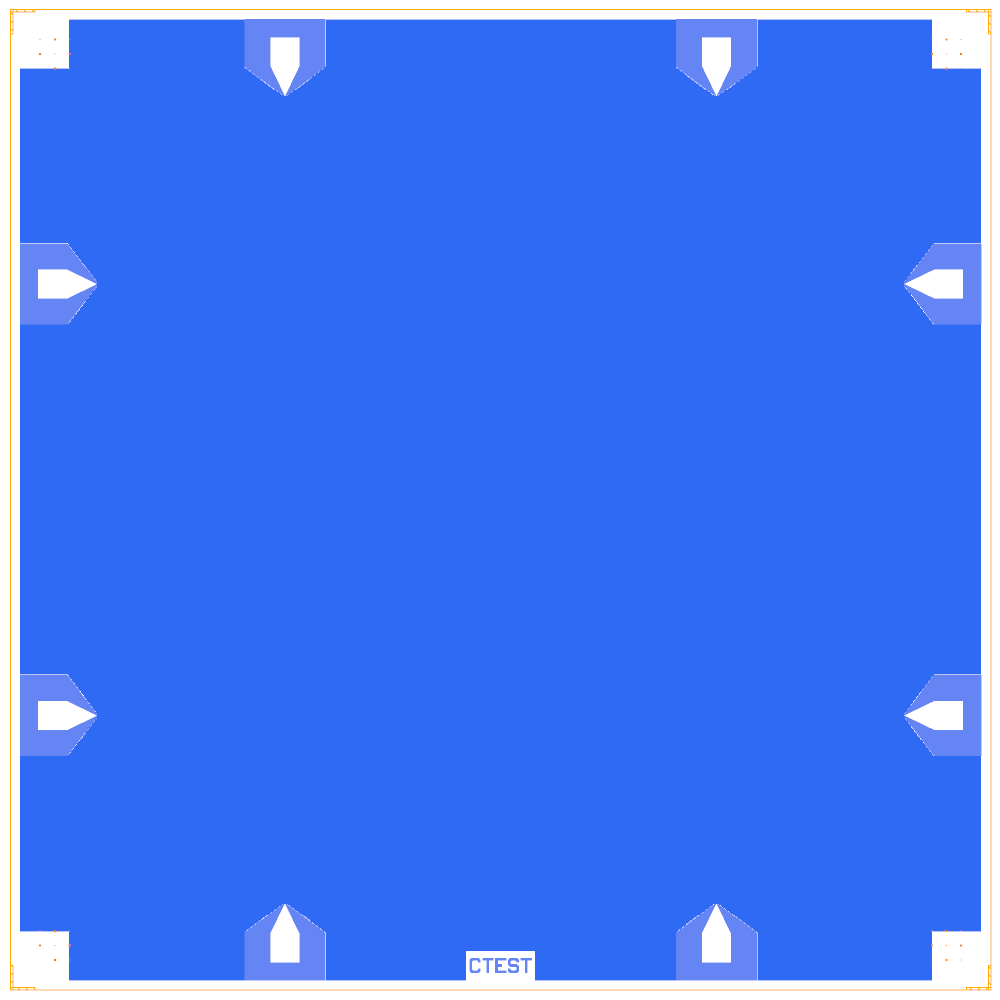

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/shaping/1_die.png')

In [5]:
d = Designer("shaping", box=(0, 0, 10000, 10000), launchers="SMA8", chip={"name_chip": "CTest", "with_grid": True},
             live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on WN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

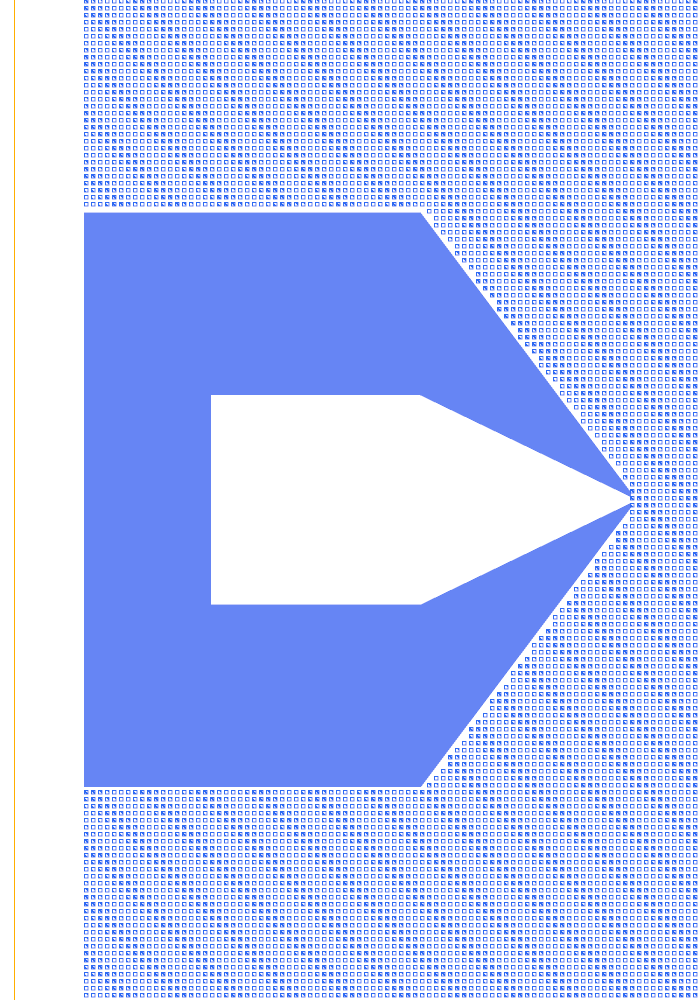

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## Design 3 · Readout: nothing before the qubit

This chip has no feedline: each readout chain starts at one of the qubit's couplers and ends on its own output
launcher, so there is nothing to place on the readout side until the qubit is there (Design 5).

## Design 4 · Qubit placement: the Swissmon

**The junction from the PDK rule.** KQC draws a SQUID in the Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

**The qubit.** A KQC `Swissmon` at (4000, 5000) µm rotated 270°, with KQC's per-arm lists: arms 190 / 96 / 160 / 96
µm long and 30 / 23 / 30 / 23 µm wide in 29.5 / 33 µm gaps, couplers 0 and 2 (235 and 205 µm) and none at 1. Ports:
`cplr0`–`cplr2`, `drive`, `flux`. The SQUID carries the trilayer junction of the cell above.

**KQC helpers, reproduced.** `cap_params` is KQC's `util.coupler_lib.cap_params` (finger or gap capacitors);
`meander_path` builds KQC's `Meander` in a scratch layout and returns its centre line in chip coordinates;
`wg_length` is the length KQC's `WaveguideCoplanar` gives a path (bends included). `T` is KQC's T geometry (arms
a/2 + b + 50 µm, the stub a/2 + b + 2a).

The picture zooms on the qubit, as the v1's did.

In [7]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


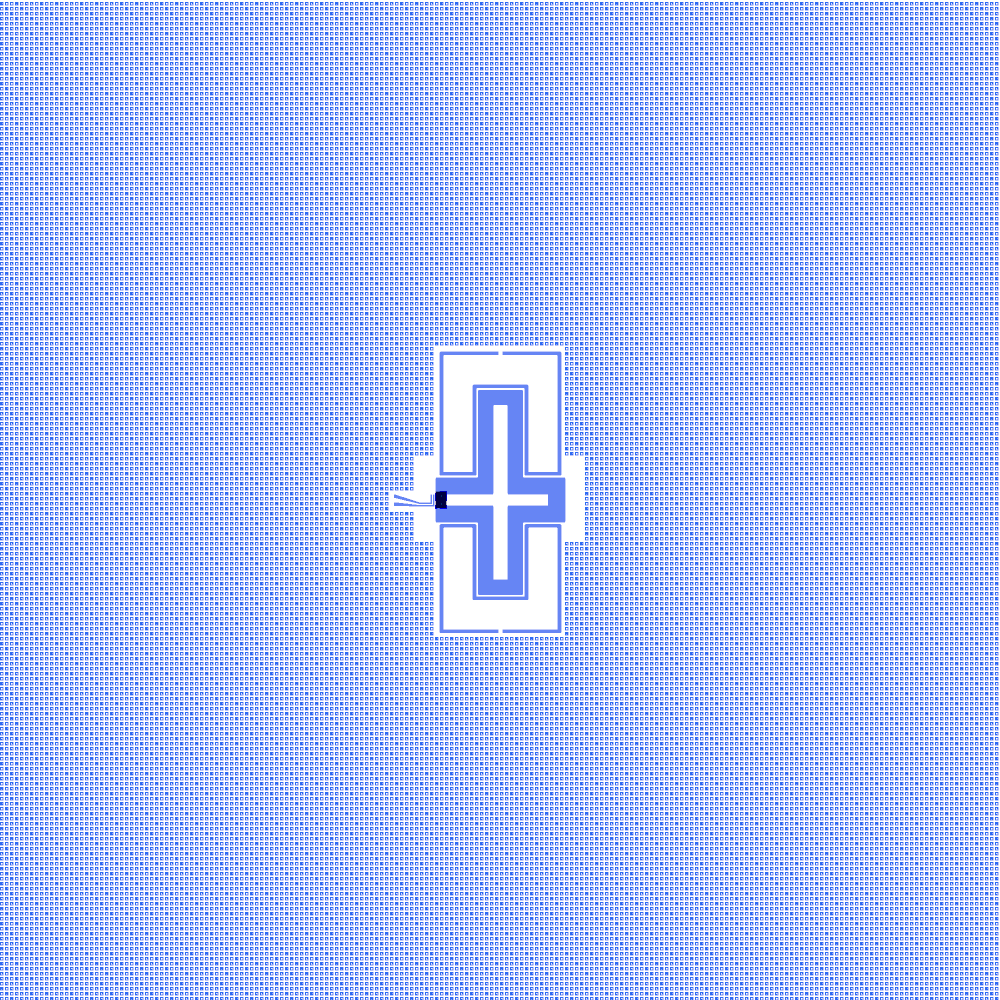

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `QB`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

WindowsPath('build/snapshots/shaping/3_components.png')

In [8]:
a, b, r = 10, 6, 100
T = dict(lengths=[a / 2 + b + 50, a / 2 + b + 50, a / 2 + b + 2 * a], port_names=["right", "left", "bottom"])
t_len, t_stub = 2 * T["lengths"][0], T["lengths"][2]       # KQC cross1_length (right ↔ left), base → bottom


def cap_params(fingers, length, kind):                     # KQC util.coupler_lib.cap_params
    p = dict(finger_number=fingers, finger_length=length, finger_gap_end=5, finger_gap=5, finger_width=15,
             ground_padding=10)
    if kind == "gap":
        p |= dict(finger_length=0, finger_gap_end=length, finger_gap=0, finger_width=10)
    return p


def meander_path(start, end, length, meanders):  # KQC Meander's centre line in chip coordinates (scratch layout)
    from kqcircuits.elements.meander import Meander
    ly = pya.Layout()
    cell = Meander.create(ly, start_point=list(start), end_point=list(end), length=length, meanders=meanders,
                          r=r, a=a, b=b)
    inst = next(cell.each_inst())                          # its one WaveguideCoplanar
    path = ly.cell(inst.cell_index).pcell_parameters_by_name()["path"]
    return [((inst.dcplx_trans * p).x, (inst.dcplx_trans * p).y)
            for p in (path.each_point() if hasattr(path, "each_point") else path)]


def wg_length(points):                                     # KQC WaveguideCoplanar(path).length()
    from kqcircuits.elements.waveguide_coplanar import WaveguideCoplanar
    ly = pya.Layout()
    return WaveguideCoplanar.create(ly, path=pya.DPath([pya.DPoint(*p) for p in points], 1), r=r, a=a, b=b).length()


with d.batch():
    q = d.add("QB", "Swissmon", at=(4000, 5000), rot=270, arm_width=[30, 23, 30, 23], arm_length=[190, 96, 160, 96],
              gap_width=[29.5, 33, 29.5, 33], island_r=2, cpl_length=[235, 0, 205], cpl_width=[60, 42, 60],
              cpl_gap=[110, 112, 110], cl_offset=[150, 150], junction=JUNCTION, **JJ_PARAMS)
layout_step(d, STEPS / "3_components.png", box=(3000, 4000, 5000, 6000), size=(1000, 1000), width=420,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")

## Design 5 · Readout: the two chains, A then B

**The two chains**, built in order because each element is placed on a port of the previous one, as in KQC. Per
chain (A up from coupler 0, B mirrored down from coupler 2):

1. the readout λ/4: a straight from the coupler to T a (KQC's length formula), the KQC meander T a → T b, and the
   shorted stub from T b's bottom arm (`d.free_end(..., term=0)`);
2. the J gap capacitor snapped to T b, T c snapped to it, the Purcell λ/4: the KQC meander from T c with the 400 µm
   leg down to the κ interdigital capacitor, and the shorted stub from T c;
3. the output from the κ capacitor to EN / ES, and the drive gap capacitor on T a with its line to NW / SW.

`wg2_len` is the 400 µm leg's length, which KQC computes once (on chain A) and reuses for chain B.

The first picture is the chip so far, the second zooms on chain A (no rebuild: the same build).

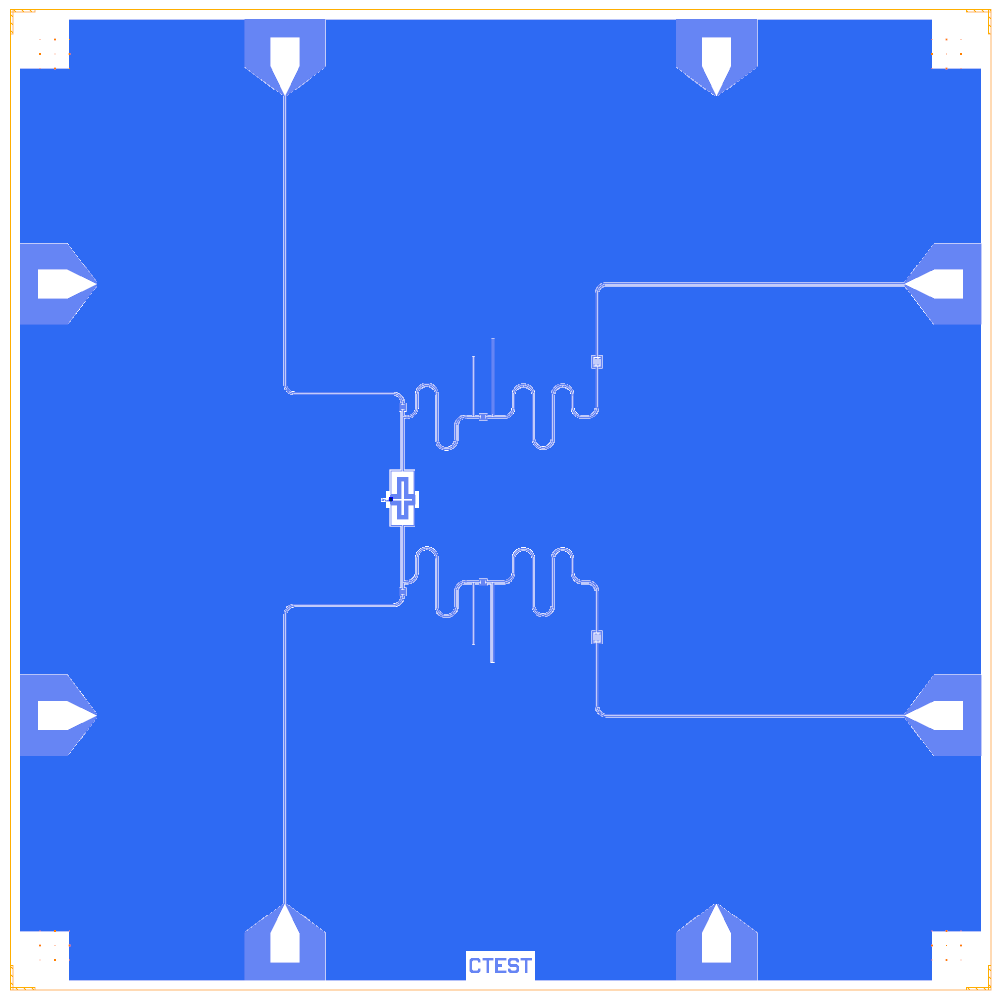

**On the chip so far:** 0 pads · 0 qubits · 13 other components · 14 routes · 0 declared couplings. **This step added** 12 component(s) `TAa`, `TAb`, `CAj`, `TAc`, `CAk`, `CAd`, `TBa`, `TBb` … (+4) and 14 route(s) `RA1`, `RA2`, `RA3`, `PA1`, `PA2`, `OA`, `DA`, `RB1` … (+6).

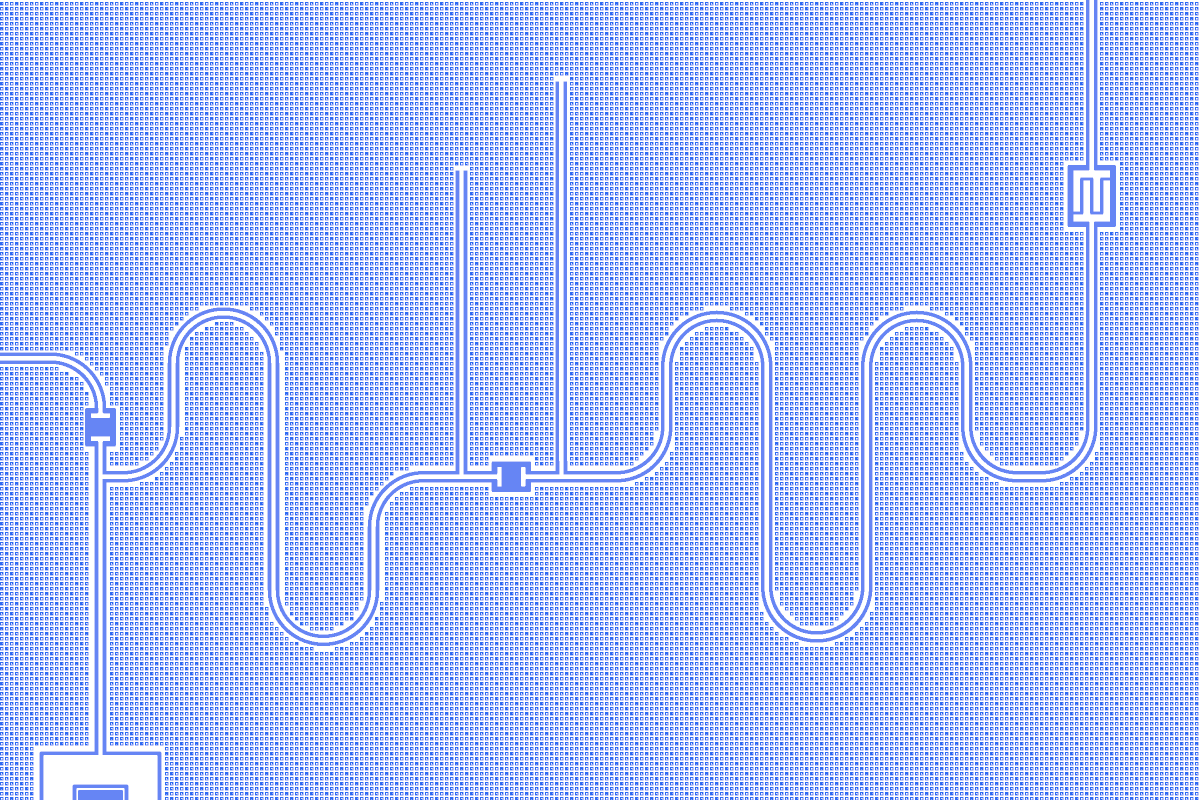

In [9]:
KQC_R = {"r": r}                                           # drawn turn radius of the meander routes (see above)
chains = (  # chain, qubit coupler, direction, readout targets, Purcell targets, caps (J, κ, drive), output, drive pad
    ("A", "cplr0", +1, [611.586, 1834.76, 611.586], [3158.32, 789.581], [37.5, 67.9, 36.2], "EN", "NW"),
    ("B", "cplr2", -1, [634.71, 1904.13, 634.71], [3253.65, 813.413], [36.8, 71.5, 36.2], "ES", "SW"),
)
wg2_len = None                                             # KQC reuses the readout chain's Purcell leg length
for ch, cplr, s, rr, pr, caps, out, pad in chains:
    up = s > 0
    L, R = ("left", "right") if up else ("right", "left")   # KQC: the readout chain uses left/right, the mirrored one right/left
    with d.batch():
        # readout λ/4: straight from the coupler → T a → meander (2) → T b → shorted stub
        cx, cy = port_xy(d, f"QB.{cplr}")
        ta = add_aligned(d, f"T{ch}a", "WaveguideCoplanarSplitter", L, (cx, cy + s * (rr[0] - t_len)), rot=90, **T)
        d.route(f"R{ch}1", f"QB.{cplr}", ta[L])
        bx, by = port_xy(d, f"T{ch}a.bottom")
        tb = add_aligned(d, f"T{ch}b", "WaveguideCoplanarSplitter", R, (bx + 630, by), rot=180 if up else 0, **T)
        path = meander_path((bx, by), (bx + 630, by), rr[1] - t_len - t_stub, 2)
        d.route(f"R{ch}2", ta.bottom, tb[R], r=10, nodes=path[1:-1]).set(params=KQC_R)
        sx, sy = port_xy(d, f"T{ch}b.bottom")
        d.route(f"R{ch}3", tb.bottom, Designer.free_end((sx, sy + s * (rr[2] - t_stub)), term=0))
        # J capacitor → T c; Purcell λ/4: T c → meander (3) → 400 µm leg → κ capacitor; T c → shorted stub
        cj = d.add(f"C{ch}j", "FingerCapacitorSquare", snap="a", to=tb[L], **cap_params(4, caps[0], "gap"))
        tc = d.add(f"T{ch}c", "WaveguideCoplanarSplitter", snap=R, to=cj.b, **T)
        lx, ly = port_xy(d, f"T{ch}c.{L}")
        m3_end = (lx + 900, ly)
        leg = [m3_end, (m3_end[0] + r, ly), (m3_end[0] + r, ly + s * 400), (m3_end[0] + r, ly + s * (400 + r))]
        wg2_len = wg2_len or wg_length(leg)
        ck = add_aligned(d, f"C{ch}k", "FingerCapacitorSquare", "a", leg[-1], rot=90 if up else 270,
                         **cap_params(4, caps[1], "interdigital"))
        path = meander_path((lx, ly), m3_end, pr[0] - t_len - wg2_len, 3)
        d.route(f"P{ch}1", tc[L], ck.a, r=10, nodes=path[1:] + leg[1:-1]).set(params=KQC_R)
        px, py = port_xy(d, f"T{ch}c.bottom")
        d.route(f"P{ch}2", tc.bottom, Designer.free_end((px, py + s * (pr[1] - t_stub)), term=0))
        # output: κ capacitor → EN / ES; drive: gap capacitor on T a → NW / SW
        kx, _ = port_xy(d, f"C{ch}k.b")
        _, oy = port_xy(d, f"chip.{out}")
        d.route(f"O{ch}", ck.b, f"chip.{out}", nodes=[(kx, oy)])
        cd = d.add(f"C{ch}d", "FingerCapacitorSquare", snap="a", to=ta[R], **cap_params(4, caps[2], "gap"))
        _, iy = port_xy(d, f"C{ch}d.b")
        nx, _ = port_xy(d, f"chip.{pad}")
        d.route(f"D{ch}", cd.b, f"chip.{pad}", nodes=[(nx, iy + s * r)])
layout_step(d, STEPS / "s5_chains.png", **CHIP)
snap(d, STEPS / "s5_chain_a.png", box=(3800, 5200, 6200, 6800), size=(1200, 800), width=480);

## Design 6 · Coupling: none beyond the chains

One qubit: it couples to its two chains through couplers 0 and 2 and the capacitors of Design 5; there is no second
qubit and no bus.

## 6 · Routes

## Design 7 · Routing: the charge and flux lines

**Charge and flux lines.** The charge line from WN ends 6 µm short of the drive port (`term2=b`); the flux line
comes from WS. Both turn one radius in from the launcher.

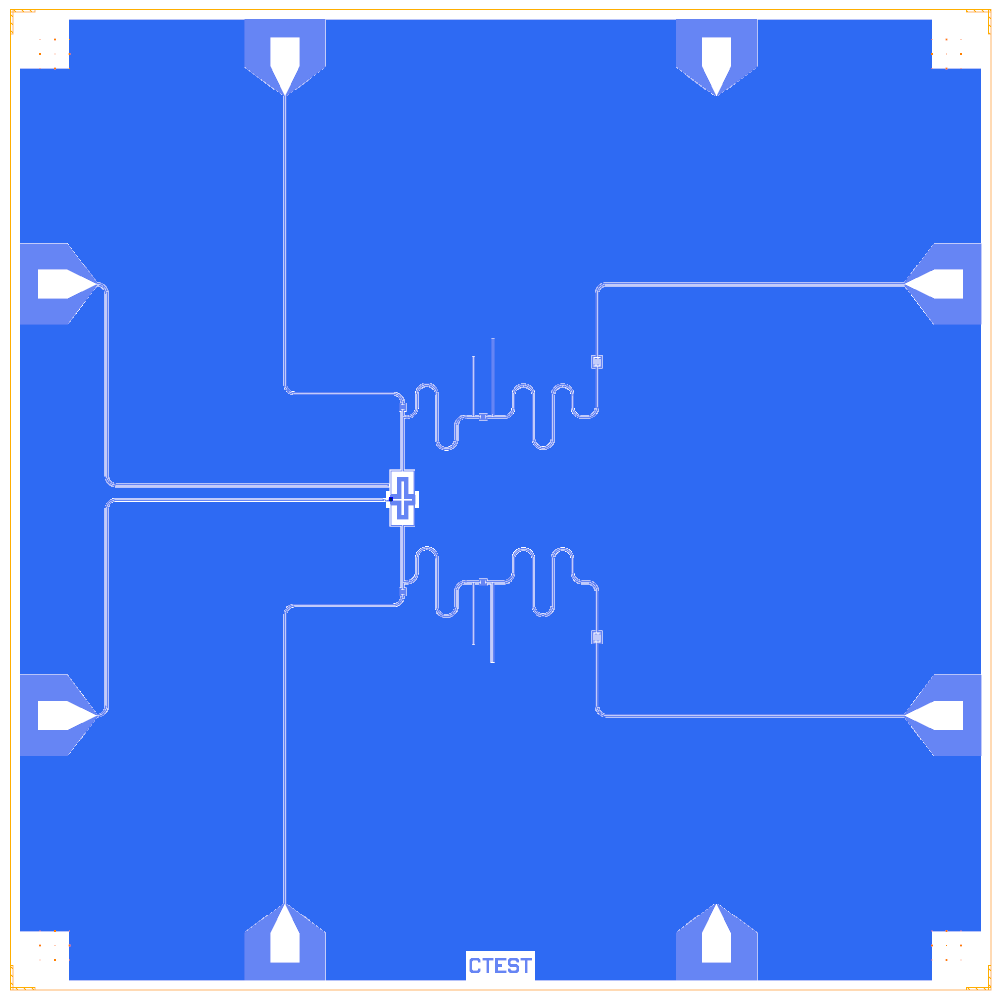

**On the chip so far:** 0 pads · 0 qubits · 13 other components · 16 routes · 0 declared couplings. **This step added** 2 route(s) `CL`, `FL`.

WindowsPath('build/snapshots/shaping/s7_control.png')

In [10]:
with d.batch():
    (wnx, _), (wsx, _) = port_xy(d, "chip.WN"), port_xy(d, "chip.WS")
    _, dy = port_xy(d, "QB.drive")
    _, fy = port_xy(d, "QB.flux")
    d.route("CL", "chip.WN", q.drive, nodes=[(wnx + r, dy)], term2=b)        # charge line, open end b = 6 µm
    d.route("FL", "chip.WS", q.flux, nodes=[(wsx + r, fy)])                  # flux line
layout_step(d, STEPS / "s7_control.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups, centring, save.** A Q3D C-matrix of the qubit alone (island, coupler pads, charge and flux lines;
150 µm margin, clear of the meanders) and per chain an eigenmode job with the qubit, both resonators and the
capacitors (100 µm margin). `center_in_die` checks that the content sits centred in the die and shifts it if it is
more than 50 µm off. Then `shaping.json` is saved with `save_design`, which compares it with the file it replaces (the previous
run's): the segments above changed how the chip is built (the charge and flux lines after the chains), not the
chip, so it should say *same design*; the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/shaping.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer shaping: 13 instances, 16 routes, live=False> → examples\designs\kqc\test_chips\shaping.json
{'RA1': 489.59, 'RA2': 1681.76, 'RA3': 580.59, 'PA1': 3036.32, 'PA2': 758.58, 'OA': 3825.09, 'DA': 4250.37, 'RB1': 512.71, 'RB2': 1751.13, 'RB3': 603.71, 'PB1': 3131.65, 'PB2': 782.41, 'OB': 3829.07, 'DB': 4257.25, 'CL': 4934.16, 'FL': 5021.83}


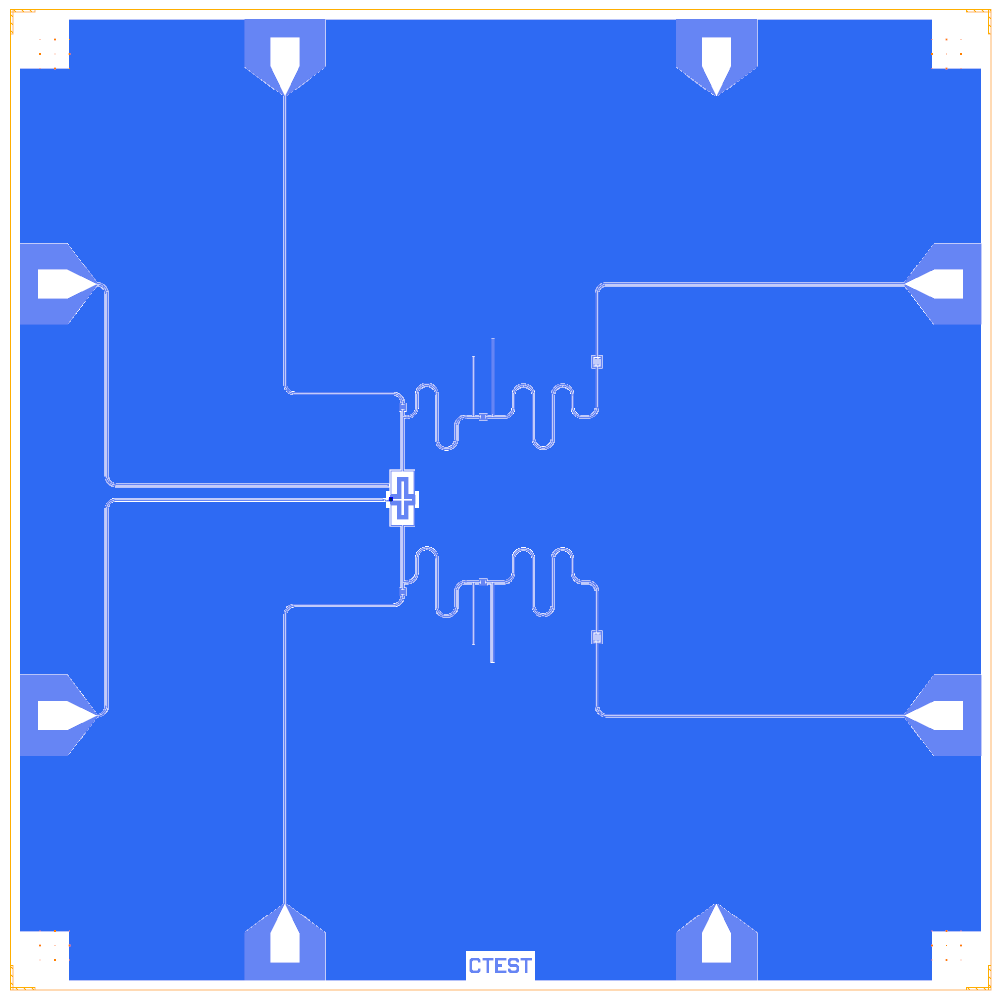

**On the chip so far:** 0 pads · 0 qubits · 13 other components · 16 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/shaping/4_routes.png')

In [11]:
d.sim_group("QB", ["QB"], margin_um=150, analyses=["q3d_cmatrix"])   # 150 µm: clear of the meanders
for ch in "AB":
    d.sim_group(f"QB_{ch}", ["QB"] + [f"{p}{ch}{x}" for p, x in (("T", "a"), ("T", "b"), ("T", "c"), ("C", "j"),
                ("C", "k"), ("C", "d"), ("R", 1), ("R", 2), ("R", 3), ("P", 1), ("P", 2))],
                margin_um=100, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "shaping.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean, with one `dangling_port` warning: the Swissmon's zero-length coupler 1 (`cpl_length = [235, 0, 205]`; the LOM puts its port on ground). No PDK design warning (device R_n 45 kΩ, f_q ≈ 6.5 GHz). `pdk_report` gives KQC's grid as the cheese ("the original design's own"), the content centred (0, 0) and "Quantcore Squid × 1".

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit. The qubit island (C and the SQUID to ground) has its coupler
nodes 0 and 2. Each coupler node carries its chain's readout λ/4 (`R*3`, one `TLres` of the chain's summed routes)
and the drive and J capacitors; the J capacitor's far node carries the Purcell λ/4 (`P*2`) and the κ capacitor
into the output launcher (50 Ω). The charge line is a drive control, the flux line a flux control.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

The whole circuit: QuCat's normal modes, the QuTiP-dressed qubit values and, per qubit, its most strongly coupled
resonator. Rough, see the LOM approximation above (taps at the open end, T arms not counted). The last table
compares each λ/4's LOM line with KQC's segment targets.

In [ ]:
res = simulate_lom(lb, d.design, max_modes=3)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
display(Markdown(pairs_md(res)))

# λ/4 lengths: LOM (sum of the chain's routes) vs KQC's segment targets (which include the T arms)
lengths = d.result.route_lengths()
rows = ["| resonator | LOM line (µm) | KQC target sum (µm) | T arms not in the LOM (µm) |", "|---|---|---|---|"]
for ch, _, _, rr, pr, *_ in chains:
    for name, routes, target in ((f"R{ch}3", ("1", "2", "3"), sum(rr)), (f"P{ch}2", ("1", "2"), sum(pr))):
        lom = sum(lengths[f"{name[0]}{ch}{k}"] for k in routes)
        rows.append(f"| {name} | {lom:.1f} | {target:.1f} | {target - lom:.1f} |")
display(Markdown("\n".join(rows)))

**From the v1 run:** five modes: the qubit at 6.680 GHz (QuCat; QuTiP-dressed 6.450 GHz, α −242 MHz; KQC's assumed 12 nH gave ≈ 5.2 GHz); the two Purcell filters at 7.476 (PB2) and 7.716 GHz (PA2), κ ≈ 28 MHz into their outputs; the two readouts at 8.239 (RB3) and 8.345 GHz (RA3), κ 0.31 / 0.33 MHz through their filters; χ of the qubit with RA3 ≈ −6.5 MHz. Each readout λ/4 is 306 µm and each filter 153 µm shorter in the LOM than KQC's targets (the T arms, last table), so these LOM frequencies sit high.

## LOM 2 · The LOM in two plots

The same result as pictures: (a) the circuit's five normal modes (QuCat; the circle is the qubit, the squares the two
readouts and the two Purcell filters; filled markers are the QuTiP dressed values of the three lowest modes), (b) the
dispersive shift |χ| of the resonators QuTiP kept. Rough, as LOM 1 says: the mode structure is right, the couplings
are not to be trusted.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="shaping: LOM (rough, see LOM 1)")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The Purcell filter's κ capacitor sets how fast the filter (and through it the readout) leaks into the output line.
Lengthen chain A's κ fingers from 67.9 to 90 µm: the filter's κ rises and, through the J capacitor, the readout's
too; the frequencies barely move. The change is made on a copy (`design_copy`), so `shaping.json` keeps KQC's
67.9 µm.

In [ ]:
d2 = design_copy(DESIGN)
d2["CAk"].set(finger_length=90)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=3)
m0, m1 = {m.label: m for m in res.modes}, {m.label: m for m in res2.modes}
display(Markdown("**CAk fingers: 67.9 → 90 µm**\n\n| mode | kind | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].kind} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |"
                     for k in m0 if k in m1)))

**Result (from the v1 run).** the filter PA2 moves from 7.716 to 7.649 GHz (−67 MHz) and its κ from 27.9 to 41.7 MHz; the readout RA3's κ rises from 0.326 to 0.339 MHz (through the J capacitor); the qubit and chain B do not move.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/test_chips/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: a Q3D C-matrix of the qubit, and per chain an eigenmode job with the qubit (its junction a lumped
port), both resonators and the capacitors: the lines leaving the box (output, drive, the other chain's
straight, charge and flux lines) end in 50 Ω, so the solve gives the readout and Purcell modes, their χ
and the Purcell-filtered κ.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/test_chips/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["QB"])               # Q3D C-matrix of the qubit (the group's own analysis)
jobs_eig = export_sims(DESIGN, ["QB_A", "QB_B"], analysis="eigenmode_epr")   # the two chains (their own analysis)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix of the qubit

The qubit alone (150 µm margin, clear of the meanders): the island and the lines the box cuts (charge line, both
chains' straights) as named nets, each named after its LOM node, so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The two chain boxes in HFSS eigenmode (Simulate 1's table: the qubit with the junction as a lumped L_J ‖ C_J sheet,
both resonators and the capacitors of one chain; the output, drive, charge and flux lines and the other chain's
straight end in 50 Ω). Each solve gives the readout and Purcell modes, their χ and the Purcell-filtered κ; pyEPR runs
inside qcc's own AEDT (never KQC's `run_pyepr_t1_estimate.py`).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of chain A's box: the drive line → readout → J → filter → κ → output line is a
transmission path, so the readout shows up as a transmission peak through the filter, not as a hanger notch (the
notch fit may find nothing here; κ then comes from the eigenmode Q, Results 2). The library cannot hand the solved
eigenmode **mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest
thing: the same sim group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode
nearest RA3 (the LOM's linear f before the eigenmode is solved) and a fast sweep around it.

In [ ]:
lin = {m.label: m for m in res.modes}           # the LOM's normal modes (LOM 1): QB, RA3, RB3, PA2, PB2

f_drv = lin["RA3"].f_GHz   # the LOM's (linear) RA3 frequency
jobs_drv = driven_from_eigenmode(DESIGN, "QB_A", jobs_eig["QB_A"][0], keep_eig["QB_A"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB_A"]:
    display(Markdown(driven_md(keep_drv["QB_A"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"QB": res.params.get("QB.f_q_GHz"), **{k: m.f_GHz for k, m in lin.items() if m.kind == "resonator"}}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each chain's eigenmode job in the LOM's terms: the qubit's mode is the one its SQUID participates in most, the
readout's the remaining mode nearest the LOM's; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The Purcell filter is the mode `match_modes` pairs
with the LOM's filter frequency (order-preserving with the readout, so the two cannot swap); its κ = f/Q.

In [ ]:
fem_values = {}
for ch, rd, pf in (("A", "RA3", "PA2"), ("B", "RB3", "PB2")):
    keep = keep_eig.get(f"QB_{ch}")
    if not keep:
        continue
    vals = epr_values(keep, {"QB": rd}, {rd: lin[rd].f_GHz})
    fem_values.update({(k if k.startswith(rd) else f"chain {ch}: {k}"): x for k, x in vals.items() if k != "modes"})
    e = match_modes(keep, {pf: lin[pf].f_GHz, rd: lin[rd].f_GHz}).get(pf)
    if e:
        fem_values[f"{pf}.f_GHz"], fem_values[f"{pf}.kappa_MHz"] = e["f_GHz"], 1e3 * e["f_GHz"] / e["Q"]
if keep_drv["QB_A"]:
    fem_values.update({f"driven {k}": x for k, x in driven_values(keep_drv["QB_A"], "RA3", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n"
                     + "\n".join(f"| `{k}` | {x:.5g} |" for k, x in fem_values.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list the qubit's f_q and α, each readout's f_r, "
          "χ and κ, and each Purcell filter's f and κ.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the qubit's capacitance estimates by the C-matrix values (matched by net
name; the chains keep their estimates) and the same LOM runs again. **FEM directly:** the eigenmode values of
Results 2 (the qubit from chain A's box). The left column is the LOM on the component estimates (LOM 1; the
resonators' linear QuCat values). Expect large differences on the resonators: the LOM leaves out the T arms (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

lom = {"QB.f_q_GHz": res.params.get("QB.f_q_GHz"), "QB.alpha_MHz": res.params.get("QB.alpha_MHz")}
for k in ("RA3", "RB3", "PA2", "PB2"):
    lom[f"{k}.f_GHz"], lom[f"{k}.kappa_MHz"] = lin[k].f_GHz, lin[k].kappa_MHz
rows = []
if keep_q3d["QB"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["QB"]), max_modes=3)
    got = {"QB.f_q_GHz": on_fem.params.get("QB.f_q_GHz"), "QB.alpha_MHz": on_fem.params.get("QB.alpha_MHz")}
    rows += [(k, lom[k], got[k], "LOM on the Q3D C-matrix") for k in got]
fq = {"QB.f_q_GHz": fem_values.get("chain A: QB.f_q_GHz"), "QB.alpha_MHz": fem_values.get("chain A: QB.alpha_MHz")}
rows += [(k, lom[k], x, "eigenmode + pyEPR (chain A)") for k, x in fq.items() if x is not None]
rows += [(k, lom[k], fem_values[k], "eigenmode") for k in lom if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the qubit's f_q and α and each resonator's f and κ "
          "of the LOM next to the LOM on the Q3D C-matrix and next to the eigenmodes, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `Shaping` states no frequencies, so this notebook sets one as an exercise: **the qubit at 6.25 GHz**, ≈ 0.2 GHz
below where the LOM puts it (from the v1 run: 6.450 GHz, QuTiP), further below the Purcell filters' band (7.48 /
7.72 GHz in the v1 run), where the filters suppress its decay into the outputs more. It is reachable inside the PDK
junction window: L_J goes from 6.73 nH to ≈ 7.16 nH, R_n ≈ 48 kΩ (`pdk_lj_bounds` keeps the feedback within
40–50 kΩ). The chains are not targeted: the LOM's tapped couplings are rough (LOM 1).

The targets go on a copy (`target_copy` → `build/shaping_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.25 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB": {"f_q_GHz": 6.25}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/shaping/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's qubit Q3D job is exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB',)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `shaping.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/kqc/test_chips/shaping.json` rebuilds `build/shaping.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK
band is added. In the v1 run: 1/0 888 428 polygons, 3/0 868 989 (the keep-outs merge with neighbouring grid holes), 888 419 grid holes; the export takes ≈ 20 s here. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/shaping.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB_A", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

The full chip (KQC's grid fills the ground as one tone at this scale); the readout chain; the qubit; its SQUID and
flux line; the J capacitor between the two T's; the die frame's south-west corner (dicing L on 1000/0, 3 × 3
alignment grid on 1001/0); and the qubit in the **fab view** (the mask from Fab 1: 1/0 and 3/0 with the grid
holes, the trilayer layers). The chip boundary 100/0 is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "shaping.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "shaping_readout.png", box=(3800, 5200, 6200, 6800), size=(1600, 1067), width=640)
show_snapshot(d, OUT / "shaping_qb.png", box=(3600, 4600, 4400, 5400), width=420)
fx, fy = port_xy(d, "QB.flux")
show_snapshot(d, OUT / "shaping_squid.png", box=(fx - 20, fy - 70, fx + 120, fy + 70), width=360)
x, y = port_xy(d, "CAj.a")
show_snapshot(d, OUT / "shaping_cap_j.png", box=(x - 60, y - 80, x + 140, y + 120), width=360)
show_snapshot(d, OUT / "shaping_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "shaping_fab.oas", OUT / "shaping_fab_qb.png", box=(3750, 4750, 4250, 5250),
          size=(1200, 1200), width=420);   # fab view: 1/0 + 3/0 with the grid holes, junction layers

**Reference: XOR with the source.** KQC's `Shaping` built stand-alone, XOR-ed layer by layer with this build (the
union of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped).
The reference gets `name_brand="QC"`, the brand text a KQC frame would write here. **The rebuild is expected to
differ** by design: the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (KQC's Manhattan
SQUID vs the trilayer SQUID), the ground grid (KQC's stand-alone build has none), and the launchers with their
first line legs (80 µm deeper here). The column "> 1 nm" is the XOR shrunk by one database unit: what is left there
is a real difference, not a rounding sliver. A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.shaping import Shaping as KqcChip

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, name_brand="QC").cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "shaping_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) |", "|---|---|---|"]
total = 0.0
for name in sorted(set(mine) | set(theirs)):
    if not name or name in ("refpoints", "instance_names", "ports"):
        continue
    x = ((kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region())
         ^ (kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()))
    if x.is_empty():
        continue
    total += x.area() * ref.dbu ** 2
    table.append(f"| {name} | {x.area() * ref.dbu ** 2:.3g} | {x.sized(-1).area() * ref.dbu ** 2:.3g} |")
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "shaping_kqc_original.oas", OUT / "shaping_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**From the v1 run:** the total XOR is 1.5 × 10⁸ µm², all from the expected differences: the qcc frame layers (the boundary layer covers the whole die, 1 × 10⁸ µm², plus the markers), the ground grid (2.2 × 10⁷) and its avoidance (1.3 × 10⁷), KQC's ChipFrame (dicing edge, EBL and airbridge marker shapes), the Manhattan vs trilayer SQUID layers (400–600 µm² each) and the base etch (8.9 × 10⁶ µm²: KQC's frame band and the 80 µm launcher shift).

## Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; both chains with KQC's segment formulas and meander centre lines; the charge, flux, drive and output lines; the sim groups; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; the Quantcore trilayer SQUID (f_q ≈ 6.5 GHz instead of ≈ 5.2 GHz) |
| **simplified** | the four meanders are routes on KQC's centre lines; the LOM's tapped couplings (rough) |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | 4 jobs exported (`build/jobs/shaping_*`: 1 Q3D, 2 eigenmode, chain A's driven run), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, no readout line before the qubit, the qubit, both chains — after the qubit, element by element —, no coupling, the charge and flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (the qubit at 6.25 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn SQUID keeps its fingers (size it with `trilayer_junction`) |